## Device

In [1]:
import torch
import gc

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM total:", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2), "GB")

Using device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
VRAM total: 6.05 GB


## Dataset dan transform

In [2]:
import os
from torchvision import datasets, transforms

DATA_DIR = 'archive'
IMG_SIZE = 384
RESIZE_SIZE = 420

full_dataset = datasets.ImageFolder(DATA_DIR)
class_names = full_dataset.classes
NUM_CLASSES = len(class_names)
print(f"{NUM_CLASSES} kelas Dengan {len(full_dataset)} gambar.")

data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((RESIZE_SIZE, RESIZE_SIZE)),
        transforms.RandomCrop(IMG_SIZE),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(7),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize((RESIZE_SIZE, RESIZE_SIZE)),
        transforms.CenterCrop(IMG_SIZE),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

45 kelas Dengan 14376 gambar.


## Persebaran kelas dataset

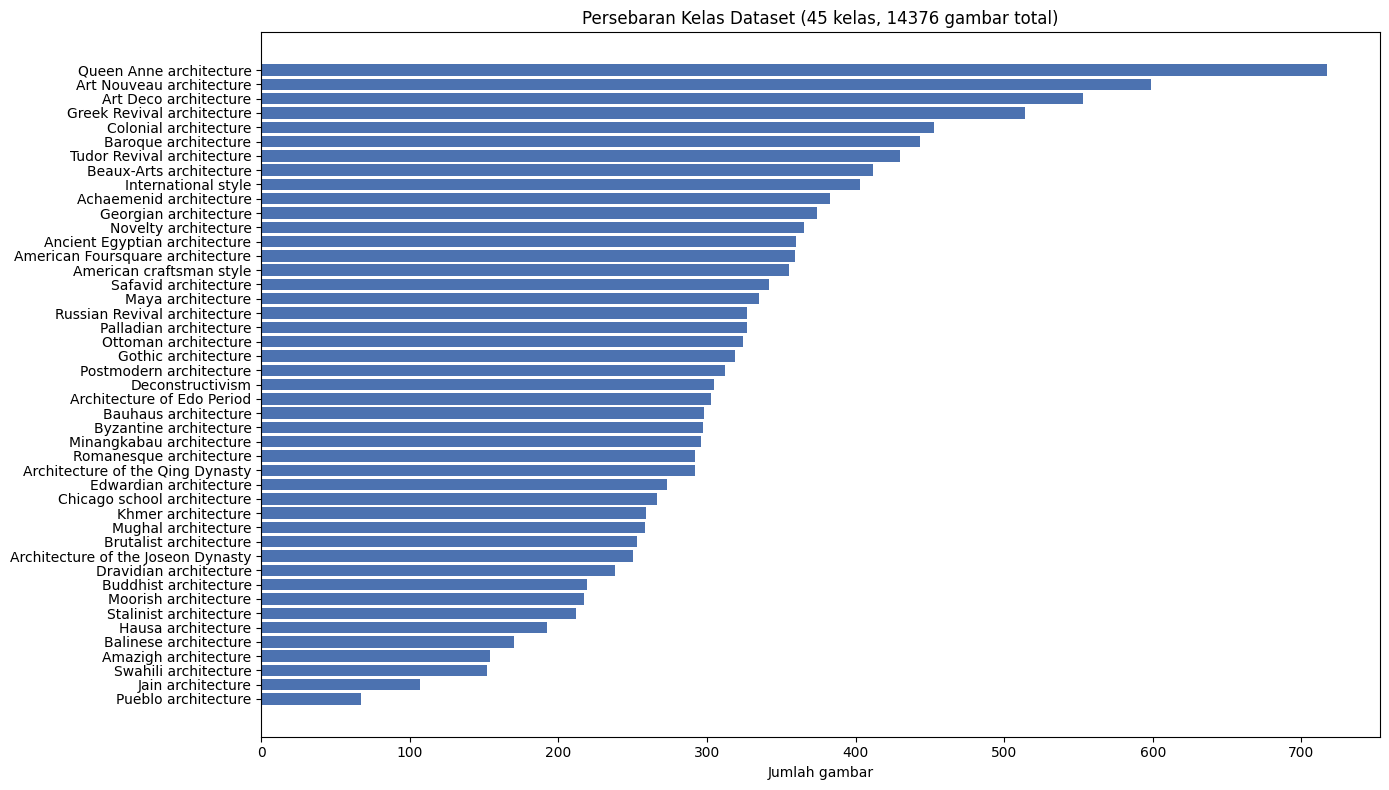

Jumlah gambar per kelas, min 67, max 717, mean 319.5


In [3]:
import matplotlib.pyplot as plt
import numpy as np

class_counts = np.bincount(full_dataset.targets, minlength=NUM_CLASSES)
order = np.argsort(class_counts)[::-1]

plt.figure(figsize=(14, 8))
plt.barh([class_names[i] for i in order][::-1], [class_counts[i] for i in order][::-1], color='#4C72B0')
plt.xlabel('Jumlah gambar')
plt.title(f'Persebaran Kelas Dataset ({NUM_CLASSES} kelas, {len(full_dataset)} gambar total)')
plt.tight_layout()
plt.show()

print(f"Jumlah gambar per kelas, min {class_counts.min()}, max {class_counts.max()}, mean {class_counts.mean():.1f}")

CutMix/MixUp

In [4]:
import torch
from torch.utils.data import Dataset
from torchvision.transforms import v2

class MapDataset(Dataset):
    def __init__(self, dataset, indices, transform=None):
        self.dataset = dataset
        self.indices = indices
        self.transform = transform
    def __getitem__(self, i):
        x, y = self.dataset[self.indices[i]]
        if self.transform: x = self.transform(x)
        return x, y
    def __len__(self): return len(self.indices)

cutmix = v2.CutMix(num_classes=NUM_CLASSES)
mixup = v2.MixUp(num_classes=NUM_CLASSES)
cutmix_or_mixup = v2.RandomChoice([cutmix, mixup])
CUTMIX_MIXUP_PROB = 0.5

def cutmix_mixup_collate_fn(batch):
    inputs, labels = torch.utils.data.default_collate(batch)
    if torch.rand(1).item() < CUTMIX_MIXUP_PROB:
        return cutmix_or_mixup(inputs, labels)
    return inputs, labels

## Stratified split (test 10%, held-out) + 5-fold CV di sisa pool

In [5]:
import json
import time
import numpy as np
from sklearn.model_selection import StratifiedKFold, train_test_split

TEST_FRAC = 0.10
N_FOLDS = 5
RANDOM_STATE = 42
CHECKPOINT_DIR = 'checkpoint_VIT-1'
RUN_ID = 'vit_b16-1'
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

all_filepaths = np.array([p for p, _ in full_dataset.samples])
all_targets = np.array(full_dataset.targets)
all_idx = np.arange(len(full_dataset.samples))

pool_idx, test_idx = train_test_split(
    all_idx, test_size=TEST_FRAC, stratify=all_targets, random_state=RANDOM_STATE
)

print(f"Pool untuk CV: {len(pool_idx)} gambar | Held-out test: {len(test_idx)} gambar")

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
fold_splits_local = list(skf.split(pool_idx, all_targets[pool_idx]))
fold_splits = [(pool_idx[tr], pool_idx[va]) for tr, va in fold_splits_local]

fold_export = []
for i, (train_idx, val_idx) in enumerate(fold_splits):
    fold_export.append({
        'fold': i + 1,
        'val_filepaths': [full_dataset.samples[j][0] for j in val_idx],
        'val_labels': [full_dataset.samples[j][1] for j in val_idx],
    })

RUN_TIMESTAMP = time.strftime('%Y%m%d_%H%M%S')
fold_split_path = os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_fold_splits_{RUN_TIMESTAMP}.json')
with open(fold_split_path, 'w') as f:
    json.dump({
        'class_names': class_names,
        'folds': fold_export,
        'held_out_test_filepaths': [full_dataset.samples[j][0] for j in test_idx],
    }, f)
print(f"Pembagian {N_FOLDS} fold (held-out test terpisah) diekspor ke {fold_split_path}")

Pool untuk CV: 12938 gambar | Held-out test: 1438 gambar
Pembagian 5 fold (held-out test terpisah) diekspor ke checkpoint_VIT-1/vit_b16-1_fold_splits_20261012_115545.json


## Jumlah data gambar (train, val, test)

In [6]:
print(f"Total gambar keseluruhan : {len(full_dataset)}")
print(f"Held-out test            : {len(test_idx)} gambar ({len(test_idx)/len(full_dataset)*100:.1f}%)")
print(f"Pool untuk CV (train+val) : {len(pool_idx)} gambar ({len(pool_idx)/len(full_dataset)*100:.1f}%)")
print()
for i, (train_idx_i, val_idx_i) in enumerate(fold_splits):
    print(f"Fold {i + 1}: train = {len(train_idx_i)} gambar | val = {len(val_idx_i)} gambar")

Total gambar keseluruhan : 14376
Held-out test            : 1438 gambar (10.0%)
Pool untuk CV (train+val) : 12938 gambar (90.0%)

Fold 1: train = 10350 gambar | val = 2588 gambar
Fold 2: train = 10350 gambar | val = 2588 gambar
Fold 3: train = 10350 gambar | val = 2588 gambar
Fold 4: train = 10351 gambar | val = 2587 gambar
Fold 5: train = 10351 gambar | val = 2587 gambar


## Fungsi satu epoch (dipakai stage 1 maupun stage 2)

In [7]:
import torch
import torch.nn as nn

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

def run_epoch(model, loader, size, optimizer=None, clip_norm=None, ema=None):
    train_mode = optimizer is not None
    model.train() if train_mode else model.eval()

    running_loss = 0.0
    running_correct = 0

    with torch.set_grad_enabled(train_mode):
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            if train_mode:
                optimizer.zero_grad()

            outputs = model(inputs)
            loss = criterion(outputs, labels)
            preds = outputs.argmax(1)

            if train_mode:
                loss.backward()
                if clip_norm is not None:
                    torch.nn.utils.clip_grad_norm_(model.parameters(), clip_norm)
                optimizer.step()
                if ema is not None:
                    ema.update(model)

            running_loss += loss.item() * inputs.size(0)
            hard_labels = labels.argmax(1) if labels.ndim == 2 else labels
            running_correct += (preds == hard_labels).sum().item()

    return running_loss / size, running_correct / size

## TRAIN 1 ENCODER FREZEE

In [8]:
import torch.nn as nn
import torch.optim as optim
from torchvision import models

def build_stage1_model():
    weights = models.ViT_B_16_Weights.IMAGENET1K_SWAG_E2E_V1
    model = models.vit_b_16(weights=weights)
    for param in model.parameters():
        param.requires_grad = False
    model.heads = nn.Sequential(
        nn.Linear(768, 512),
        nn.ReLU(),
        nn.Dropout(0.4),
        nn.Linear(512, NUM_CLASSES)
    )
    for param in model.heads.parameters():
        param.requires_grad = True
    return model.to(device)

def train_stage1(model, dataloaders, dataset_sizes, epochs=8, verbose_prefix=""):
    optimizer = optim.Adam([
        {'params': model.heads.parameters(), 'lr': 1e-3, 'weight_decay': 1e-3}
    ])
    for epoch in range(epochs):
        train_loss, train_acc = run_epoch(model, dataloaders['train'], dataset_sizes['train'], optimizer)
        val_loss, val_acc = run_epoch(model, dataloaders['val'], dataset_sizes['val'])
        print(f"{verbose_prefix}Epoch {epoch + 1}/{epochs} | train_loss {train_loss:.4f} acc {train_acc:.4f} | val_loss {val_loss:.4f} acc {val_acc:.4f}")
    del optimizer
    torch.cuda.empty_cache()
    gc.collect()
    return model

## TRAIN 2 (UNFREZE 4 BLOCK)

In [9]:
import copy
import torch.optim as optim

def train_stage2(model, dataloaders, dataset_sizes, epochs=80, unfreeze_blocks=4, verbose_prefix=""):
    for param in model.encoder.layers[-unfreeze_blocks:].parameters():
        param.requires_grad = True

    optimizer = optim.Adam([
        {'params': model.encoder.layers[-unfreeze_blocks:].parameters(), 'lr': 5e-5, 'weight_decay': 1e-4},
        {'params': model.heads.parameters(), 'lr': 1e-3, 'weight_decay': 1e-3}
    ])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=5)

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_acc = 0.0
    best_model_wts = copy.deepcopy(model.state_dict())

    for epoch in range(epochs):
        train_loss, train_acc = run_epoch(model, dataloaders['train'], dataset_sizes['train'], optimizer)
        val_loss, val_acc = run_epoch(model, dataloaders['val'], dataset_sizes['val'])

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        print(f"{verbose_prefix}Epoch {epoch + 1}/{epochs} | train_loss {train_loss:.4f} acc {train_acc:.4f} | val_loss {val_loss:.4f} acc {val_acc:.4f}")

        scheduler.step(val_acc)

        if val_acc > best_acc:
            best_acc = val_acc
            best_model_wts = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_model_wts)
    del optimizer, scheduler
    torch.cuda.empty_cache()
    gc.collect()
    return model, history, best_acc

## Loop 5 fold

In [10]:
import numpy as np
from torch.utils.data import DataLoader

BATCH_SIZE = 24
NUM_WORKERS = os.cpu_count()

fold_results = []

def format_duration(seconds):
    h, rem = divmod(int(seconds), 3600)
    m, s = divmod(rem, 60)
    return f"{h:02d}:{m:02d}:{s:02d}"

cv_training_start = time.time()

for fold_idx, (train_idx, val_idx) in enumerate(fold_splits):
    print(f"\n FOLD {fold_idx + 1}/{N_FOLDS} ")

    train_dataset = MapDataset(full_dataset, train_idx, transform=data_transforms['train'])
    val_dataset = MapDataset(full_dataset, val_idx, transform=data_transforms['val'])
    dataloaders = {
        'train': DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
                             pin_memory=True, collate_fn=cutmix_mixup_collate_fn),
        'val': DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
    }
    dataset_sizes = {'train': len(train_dataset), 'val': len(val_dataset)}

    model = build_stage1_model()
    model = train_stage1(model, dataloaders, dataset_sizes, epochs=8, verbose_prefix="  [TRAIN 1] ")
    model, history, best_acc = train_stage2(model, dataloaders, dataset_sizes, epochs=80,
                                             unfreeze_blocks=4, verbose_prefix="  [TRAIN 2 ")

    torch.cuda.empty_cache()
    gc.collect()

    ckpt_path = os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_fold{fold_idx + 1}.pth')
    torch.save(model.state_dict(), ckpt_path)
    print(f"Bobot fold {fold_idx + 1} disimpan di {ckpt_path}")

    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for inputs, labels in dataloaders['val']:
            outputs = model(inputs.to(device))
            preds = outputs.argmax(1).cpu().numpy()
            y_true.extend(labels.numpy())
            y_pred.extend(preds)

    fold_results.append({
        'fold': fold_idx + 1,
        'best_val_acc': best_acc,
        'history': history,
        'y_true': np.array(y_true),
        'y_pred': np.array(y_pred),
    })

    del model, dataloaders, train_dataset, val_dataset
    torch.cuda.empty_cache()
    gc.collect()

with open(os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_fold_results_{RUN_TIMESTAMP}.json'), 'w') as f:
    json.dump([{'fold': r['fold'], 'best_val_acc': r['best_val_acc']} for r in fold_results], f, indent=2)

cv_training_elapsed = time.time() - cv_training_start
print(f"\nTotal waktu training 5-fold CV: {format_duration(cv_training_elapsed)} ({cv_training_elapsed:.1f} detik)")


 FOLD 1/5 
  [TRAIN 1] Epoch 1/8 | train_loss 2.3416 acc 0.4901 | val_loss 1.6195 acc 0.6735
  [TRAIN 1] Epoch 2/8 | train_loss 2.1480 acc 0.5781 | val_loss 1.5470 acc 0.7063
  [TRAIN 1] Epoch 3/8 | train_loss 2.0583 acc 0.6143 | val_loss 1.5096 acc 0.7175
  [TRAIN 1] Epoch 4/8 | train_loss 2.0094 acc 0.6272 | val_loss 1.4814 acc 0.7226
  [TRAIN 1] Epoch 5/8 | train_loss 1.9928 acc 0.6389 | val_loss 1.4647 acc 0.7318
  [TRAIN 1] Epoch 6/8 | train_loss 1.8922 acc 0.6659 | val_loss 1.4582 acc 0.7423
  [TRAIN 1] Epoch 7/8 | train_loss 1.9381 acc 0.6672 | val_loss 1.4640 acc 0.7457
  [TRAIN 1] Epoch 8/8 | train_loss 1.9133 acc 0.6623 | val_loss 1.4368 acc 0.7488
  [TRAIN 2 Epoch 1/80 | train_loss 2.0401 acc 0.6296 | val_loss 1.4004 acc 0.7585
  [TRAIN 2 Epoch 2/80 | train_loss 1.8203 acc 0.7055 | val_loss 1.3539 acc 0.7825
  [TRAIN 2 Epoch 3/80 | train_loss 1.7168 acc 0.7440 | val_loss 1.3024 acc 0.7948
  [TRAIN 2 Epoch 4/80 | train_loss 1.5949 acc 0.7844 | val_loss 1.2874 acc 0.8087
  [T

## Ringkasan akurasi antar fold

Akurasi validasi per fold: [0.8586, 0.8547, 0.8474, 0.8612, 0.8581]
Rata rata: 0.8560   Std: 0.0048


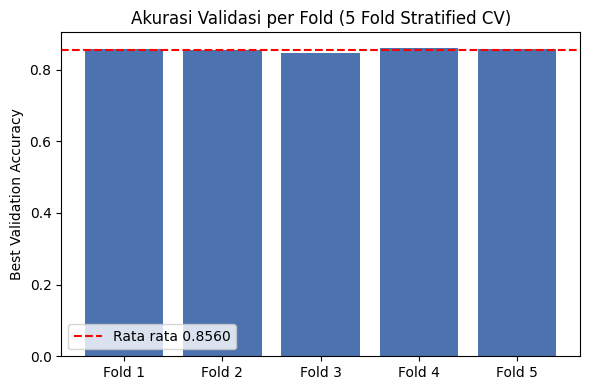

In [11]:
import matplotlib.pyplot as plt

accs = [r['best_val_acc'] for r in fold_results]
print(f"Akurasi validasi per fold: {[round(a, 4) for a in accs]}")
print(f"Rata rata: {np.mean(accs):.4f}   Std: {np.std(accs):.4f}")

plt.figure(figsize=(6, 4))
plt.bar([f"Fold {r['fold']}" for r in fold_results], accs, color='#4C72B0')
plt.axhline(np.mean(accs), color='red', linestyle='--', label=f"Rata rata {np.mean(accs):.4f}")
plt.ylabel('Best Validation Accuracy')
plt.title('Akurasi Validasi per Fold (5 Fold Stratified CV)')
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
from sklearn.metrics import precision_score, recall_score, f1_score

per_fold_metrics = []
for r in fold_results:
    y_true_f = r['y_true']
    y_pred_f = r['y_pred']
    per_fold_metrics.append({
        'fold': r['fold'],
        'accuracy': r['best_val_acc'],
        'precision_macro': precision_score(y_true_f, y_pred_f, average='macro', zero_division=0),
        'recall_macro': recall_score(y_true_f, y_pred_f, average='macro', zero_division=0),
        'f1_macro': f1_score(y_true_f, y_pred_f, average='macro', zero_division=0),
    })

for m in per_fold_metrics:
    print(f"Fold {m['fold']}: acc {m['accuracy']:.4f}  precision {m['precision_macro']:.4f}  "
          f"recall {m['recall_macro']:.4f}  f1 {m['f1_macro']:.4f}")

import pandas as pd
df_fold_metrics = pd.DataFrame(per_fold_metrics)
df_fold_metrics.to_csv(os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_fold_metrics_{RUN_TIMESTAMP}.csv'), index=False)
df_fold_metrics

Fold 1: acc 0.8586  precision 0.8728  recall 0.8615  f1 0.8642
Fold 2: acc 0.8547  precision 0.8685  recall 0.8603  f1 0.8631
Fold 3: acc 0.8474  precision 0.8588  recall 0.8493  f1 0.8516
Fold 4: acc 0.8612  precision 0.8677  recall 0.8653  f1 0.8648
Fold 5: acc 0.8581  precision 0.8729  recall 0.8636  f1 0.8646


,fold,accuracy,precision_macro,recall_macro,f1_macro
0,1,0.858578,0.872834,0.861475,0.864245
1,2,0.854714,0.868523,0.860325,0.863087
2,3,0.847372,0.858793,0.849274,0.851612
3,4,0.861229,0.867723,0.865347,0.864809
4,5,0.858137,0.872870,0.863626,0.864608


## Kurva Loss dan Akurasi Train/Val per Fold

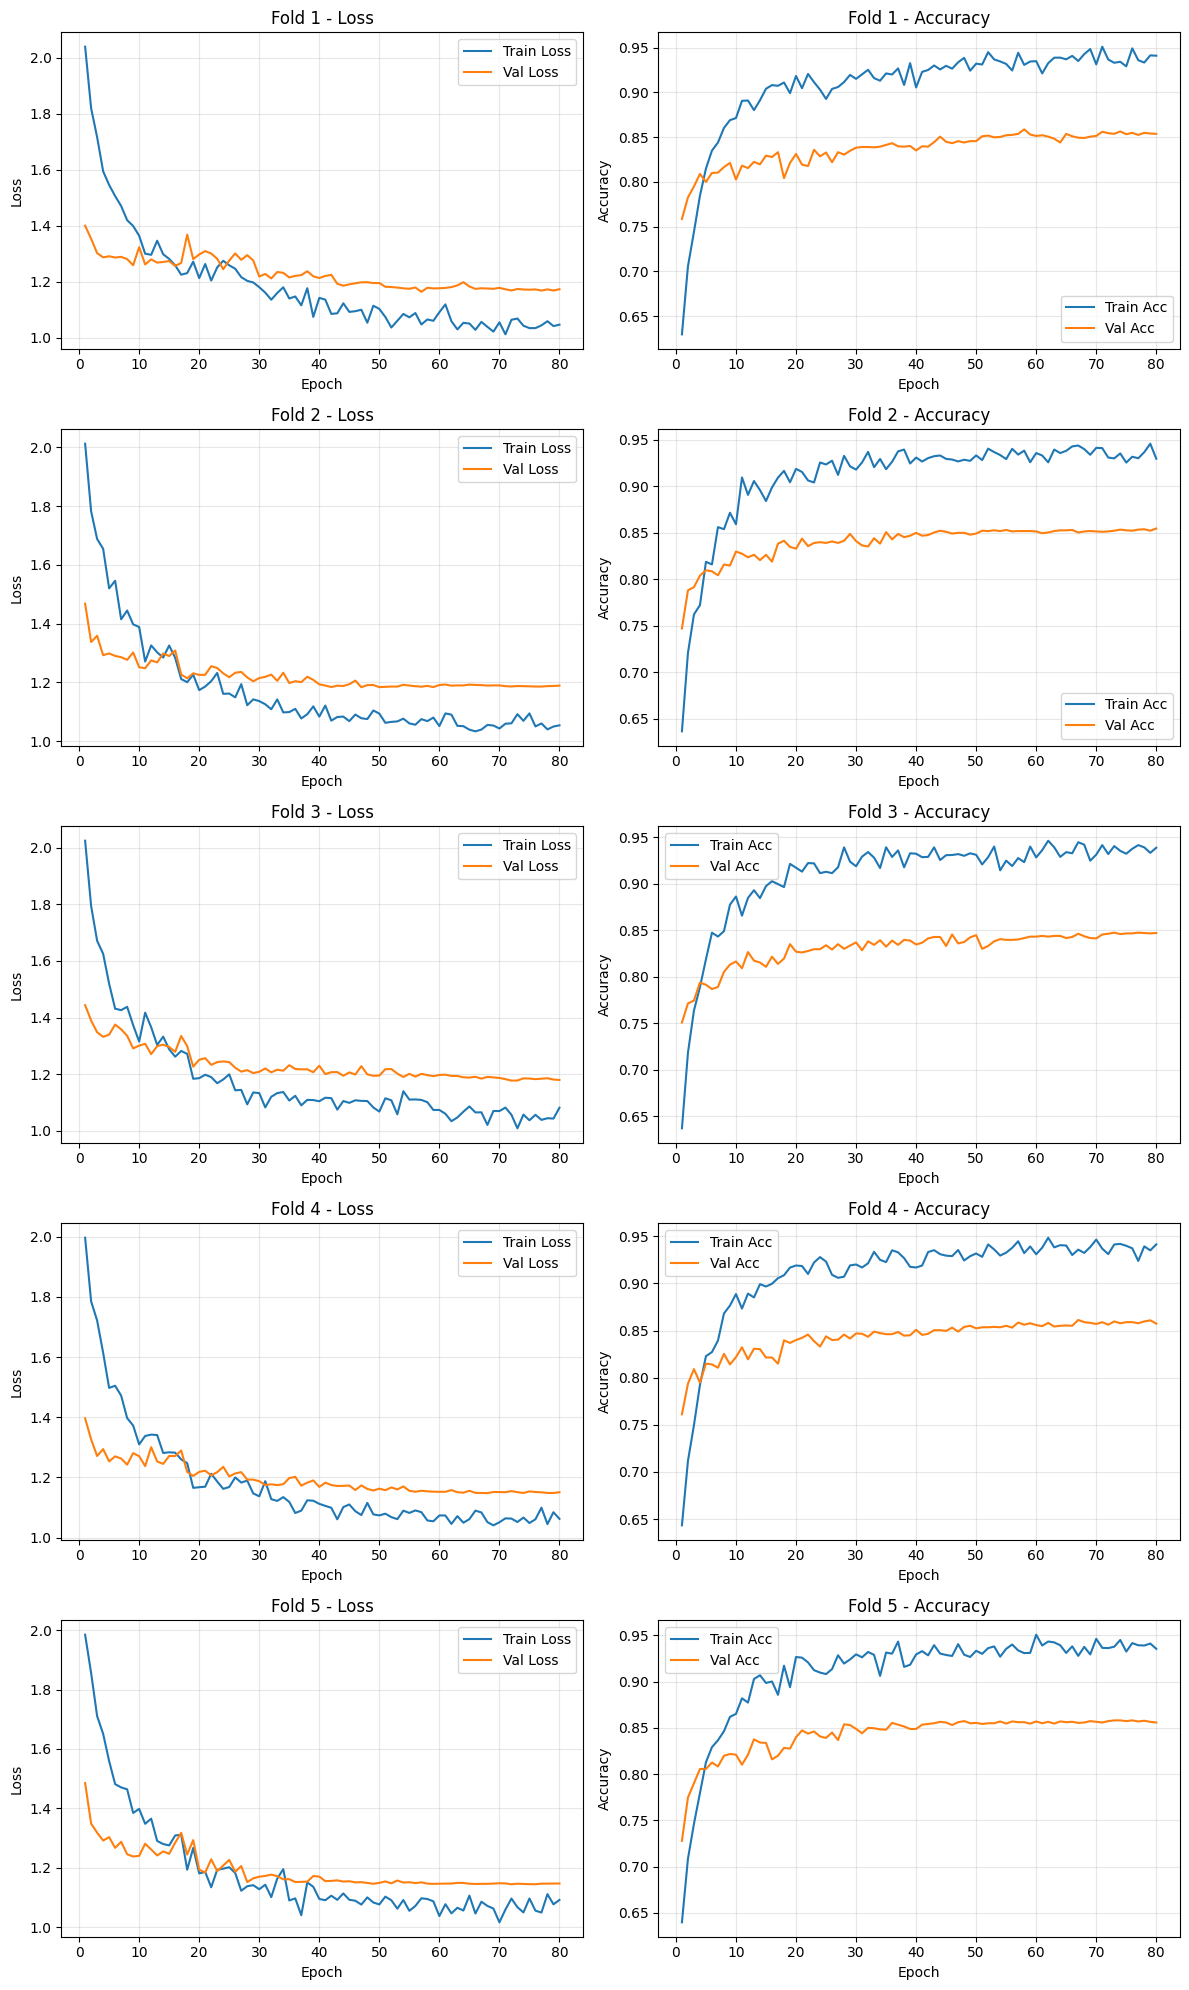

Kurva loss/akurasi per fold disimpan di checkpoint_VIT-1/vit_b16-1_loss_acc_curves_20260906_103648.png


In [13]:
n_folds = len(fold_results)
fig, axes = plt.subplots(n_folds, 2, figsize=(12, 4 * n_folds))
if n_folds == 1:
    axes = axes.reshape(1, 2)

for i, r in enumerate(fold_results):
    h = r['history']
    ep = range(1, len(h['train_loss']) + 1)

    axes[i, 0].plot(ep, h['train_loss'], label='Train Loss')
    if 'val_loss' in h and len(h['val_loss']) > 0:
        axes[i, 0].plot(ep, h['val_loss'], label='Val Loss')
    axes[i, 0].set_title(f"Fold {r['fold']} - Loss")
    axes[i, 0].set_xlabel('Epoch')
    axes[i, 0].set_ylabel('Loss')
    axes[i, 0].legend()
    axes[i, 0].grid(alpha=0.3)

    axes[i, 1].plot(ep, h['train_acc'], label='Train Acc')
    if 'val_acc' in h and len(h['val_acc']) > 0:
        axes[i, 1].plot(ep, h['val_acc'], label='Val Acc')
    axes[i, 1].set_title(f"Fold {r['fold']} - Accuracy")
    axes[i, 1].set_xlabel('Epoch')
    axes[i, 1].set_ylabel('Accuracy')
    axes[i, 1].legend()
    axes[i, 1].grid(alpha=0.3)

plt.tight_layout()
curve_path = os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_loss_acc_curves_{RUN_TIMESTAMP}.png')
plt.savefig(curve_path, dpi=150)
plt.show()
print(f"Kurva loss/akurasi per fold disimpan di {curve_path}")

## Classification report dan confusion matrix


Model Evaluation Report gabungan 5 fold (Classification Report):

                                    precision    recall  f1-score   support

           Achaemenid architecture     0.9676    0.9507    0.9591       345
              Amazigh architecture     0.9000    0.9065    0.9032       139
  American Foursquare architecture     0.8220    0.8576    0.8394       323
          American craftsman style     0.7697    0.7649    0.7673       319
     Ancient Egyptian architecture     0.9814    0.9753    0.9783       324
        Architecture of Edo Period     0.9817    0.9817    0.9817       273
Architecture of the Joseon Dynasty     0.9394    0.9644    0.9518       225
  Architecture of the Qing Dynasty     0.9544    0.9544    0.9544       263
             Art Deco architecture     0.8437    0.8454    0.8445       498
          Art Nouveau architecture     0.8557    0.9351    0.8936       539
             Balinese architecture     0.9272    0.9150    0.9211       153
              Baroqu

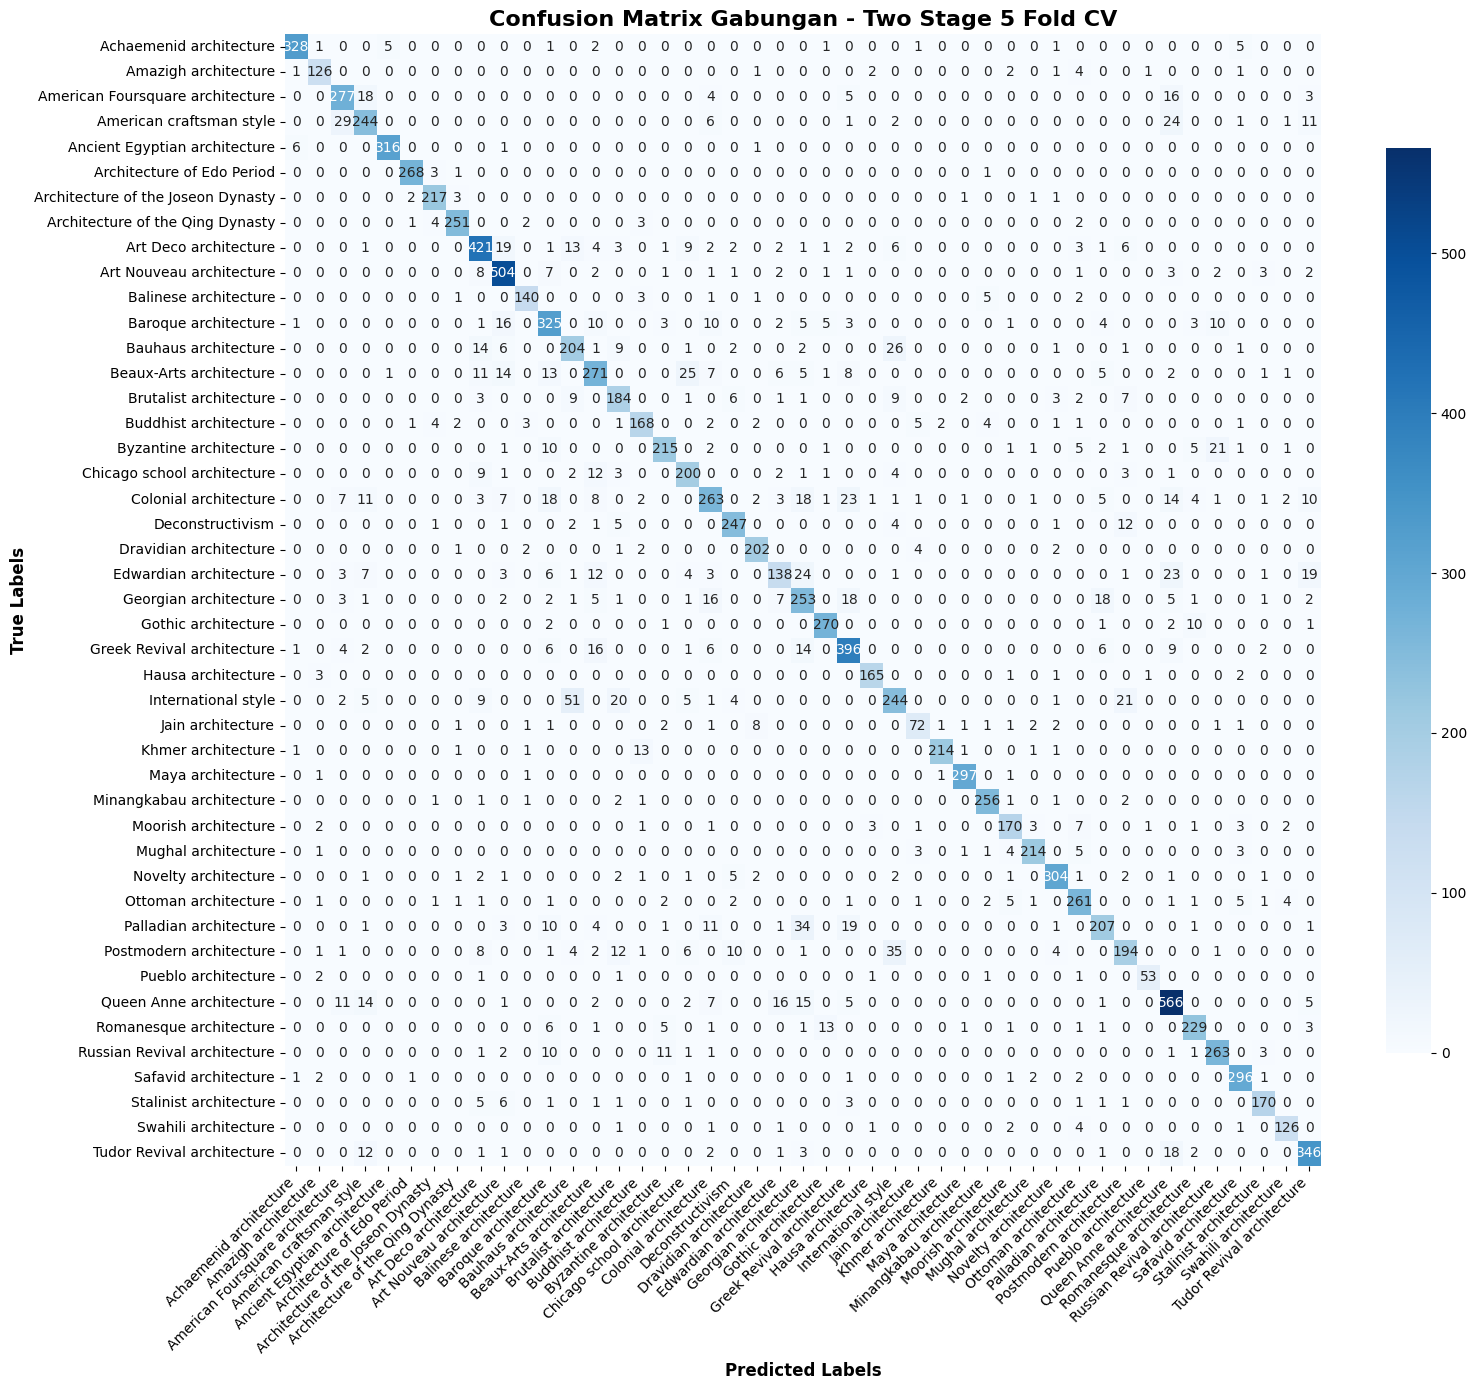

In [14]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

y_true_all = np.concatenate([r['y_true'] for r in fold_results])
y_pred_all = np.concatenate([r['y_pred'] for r in fold_results])

print("\nModel Evaluation Report gabungan 5 fold (Classification Report):\n")
print(classification_report(y_true_all, y_pred_all, target_names=class_names, digits=4))

cm = confusion_matrix(y_true_all, y_pred_all)
plt.figure(figsize=(16, 14))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            cbar_kws={'shrink': 0.8})
plt.xlabel('Predicted Labels', fontsize=12, fontweight='bold')
plt.ylabel('True Labels', fontsize=12, fontweight='bold')
plt.title('Confusion Matrix Gabungan - Two Stage 5 Fold CV', fontsize=16, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Retrain model final

In [10]:
import re
import nbformat as _nbf

def _reconstruct_fold_results_from_notebook(notebook_path, marker='FOLD {fold'):
    nb_ = _nbf.read(notebook_path, as_version=4)
    target_cell = None
    for c in nb_.cells:
        if c.get('cell_type') == 'code' and marker in c.get('source', ''):
            target_cell = c
            break
    if target_cell is None or not target_cell.get('outputs'):
        return None
    text = ''.join(o.get('text', '') for o in target_cell['outputs'] if o.get('output_type') == 'stream')
    parts = re.split(r'\n\s*FOLD (\d+)/\d+\s*\n', text)
    reconstructed = []
    for i in range(1, len(parts), 2):
        fold_num = int(parts[i])
        content = parts[i + 1]
        val_accs = [float(m) for m in re.findall(
            r'\[TRAIN 2\s*Epoch \d+/\d+ \| train_loss [\d.]+ acc [\d.]+ \| val_loss [\d.]+ acc ([\d.]+)', content)]
        if val_accs:
            reconstructed.append({'fold': fold_num, 'best_val_acc': max(val_accs), 'history': {'val_acc': val_accs}})
    return reconstructed

FOLD_RESULTS_PATH = os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_fold_results.pt')

if 'fold_results' not in dir() or not fold_results:
    if os.path.exists(FOLD_RESULTS_PATH):
        fold_results = torch.load(FOLD_RESULTS_PATH, weights_only=False)
        print(f"fold_results dimuat dari {FOLD_RESULTS_PATH} ({len(fold_results)} fold).")
    else:
        NOTEBOOK_PATH = 'VIT-B16.ipynb'
        recovered = _reconstruct_fold_results_from_notebook(NOTEBOOK_PATH)
        if recovered:
            fold_results = recovered
            print(f"fold_results direkonstruksi dari output tersimpan di notebook ({len(fold_results)} fold ditemukan).")
        else:
            print("Gagal memulihkan fold_results. Jalankan ulang CV.")
else:
    print("fold_results sudah ada di memori, tidak perlu rekonstruksi.")

fold_results direkonstruksi dari output tersimpan di notebook (5 fold ditemukan).


In [11]:
best_epochs_per_fold = []
for r in fold_results:
    val_accs = r['history']['val_acc']
    best_epoch = int(np.argmax(val_accs)) + 1 
    best_epochs_per_fold.append(best_epoch)

FINAL_STAGE2_EPOCHS = int(round(np.mean(best_epochs_per_fold)))
print(f"Epoch terbaik per fold: {best_epochs_per_fold}")
print(f"Rata rata epoch terbaik (dipakai untuk retrain final): {FINAL_STAGE2_EPOCHS}")

Epoch terbaik per fold: [58, 80, 73, 67, 73]
Rata rata epoch terbaik (dipakai untuk retrain final): 70


In [12]:
print('train_vit' in globals())
import inspect; print(inspect.signature(train_stage2))

False
(model, dataloaders, dataset_sizes, epochs=80, unfreeze_blocks=4, verbose_prefix='')


In [13]:
import inspect
print(inspect.signature(train_stage2))
print('train_vit' in globals())

(model, dataloaders, dataset_sizes, epochs=80, unfreeze_blocks=4, verbose_prefix='')
False


In [14]:
import copy
import torch.optim as optim

def train_stage1(model, dataloaders, dataset_sizes, epochs=8, verbose_prefix="", validate=True):
    optimizer = optim.Adam([
        {'params': model.heads.parameters(), 'lr': 1e-3, 'weight_decay': 1e-3}
    ])
    for epoch in range(epochs):
        train_loss, train_acc = run_epoch(model, dataloaders['train'], dataset_sizes['train'], optimizer)
        if validate:
            val_loss, val_acc = run_epoch(model, dataloaders['val'], dataset_sizes['val'])
            print(f"{verbose_prefix}Epoch {epoch + 1}/{epochs} | train_loss {train_loss:.4f} acc {train_acc:.4f} | val_loss {val_loss:.4f} acc {val_acc:.4f}")
        else:
            print(f"{verbose_prefix}Epoch {epoch + 1}/{epochs} | train_loss {train_loss:.4f} acc {train_acc:.4f}")
    del optimizer
    torch.cuda.empty_cache()
    gc.collect()
    return model

def train_stage2(model, dataloaders, dataset_sizes, epochs=80, unfreeze_blocks=4, verbose_prefix="",
                 ckpt_path=None, validate=True):
    for param in model.encoder.layers[-unfreeze_blocks:].parameters():
        param.requires_grad = True

    optimizer = optim.Adam([
        {'params': model.encoder.layers[-unfreeze_blocks:].parameters(), 'lr': 5e-5, 'weight_decay': 1e-4},
        {'params': model.heads.parameters(), 'lr': 1e-3, 'weight_decay': 1e-3}
    ])
    scheduler = (torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=5)
                 if validate else None)

    history = {'train_loss': [], 'train_acc': []}
    if validate:
        history['val_loss'] = []
        history['val_acc'] = []
    best_acc = 0.0
    best_model_wts = copy.deepcopy(model.state_dict()) if validate else None
    start_epoch = 0

    if ckpt_path is not None and os.path.exists(ckpt_path):
        ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
        model.load_state_dict(ckpt['model_state'])
        optimizer.load_state_dict(ckpt['optimizer_state'])
        if scheduler is not None and ckpt.get('scheduler_state') is not None:
            scheduler.load_state_dict(ckpt['scheduler_state'])
        history = ckpt['history']
        best_acc = ckpt['best_acc']
        best_model_wts = ckpt['best_model_wts']
        start_epoch = ckpt['epoch'] + 1
        torch.set_rng_state(ckpt['rng_state'].cpu())
        if device.type == "cuda" and ckpt.get('cuda_rng_state') is not None:
            torch.cuda.set_rng_state(ckpt['cuda_rng_state'].cpu())
        print(f"{verbose_prefix}Melanjutkan dari checkpoint: epoch {start_epoch + 1}/{epochs} "
              f"(best_acc sejauh ini {best_acc:.4f})")

    if start_epoch >= epochs:
        print(f"{verbose_prefix}Checkpoint sudah menyelesaikan {epochs} epoch, training dilewati.")
        if validate:
            model.load_state_dict(best_model_wts)
        del optimizer, scheduler
        return model, history, best_acc

    for epoch in range(start_epoch, epochs):
        train_loss, train_acc = run_epoch(model, dataloaders['train'], dataset_sizes['train'], optimizer)
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)

        if validate:
            val_loss, val_acc = run_epoch(model, dataloaders['val'], dataset_sizes['val'])
            history['val_loss'].append(val_loss)
            history['val_acc'].append(val_acc)
            print(f"{verbose_prefix}Epoch {epoch + 1}/{epochs} | train_loss {train_loss:.4f} acc {train_acc:.4f} | val_loss {val_loss:.4f} acc {val_acc:.4f}")
            scheduler.step(val_acc)
            if val_acc > best_acc:
                best_acc = val_acc
                best_model_wts = copy.deepcopy(model.state_dict())
        else:
            print(f"{verbose_prefix}Epoch {epoch + 1}/{epochs} | train_loss {train_loss:.4f} acc {train_acc:.4f}")
            best_acc = train_acc

        if ckpt_path is not None:
            tmp_path = ckpt_path + '.tmp'
            torch.save({
                'epoch': epoch,
                'model_state': model.state_dict(),
                'optimizer_state': optimizer.state_dict(),
                'scheduler_state': scheduler.state_dict() if scheduler is not None else None,
                'history': history,
                'best_acc': best_acc,
                'best_model_wts': best_model_wts,
                'rng_state': torch.get_rng_state(),
                'cuda_rng_state': torch.cuda.get_rng_state() if device.type == "cuda" else None,
            }, tmp_path)
            os.replace(tmp_path, ckpt_path)

    if validate:
        model.load_state_dict(best_model_wts)
    del optimizer, scheduler
    torch.cuda.empty_cache()
    gc.collect()
    return model, history, best_acc


def train_vit(model, dataloaders, dataset_sizes, stage1_epochs=8, stage2_epochs=80, unfreeze_blocks=4,
              prefix1="  [TRAIN 1] ", prefix2="  [TRAIN 2 ", ckpt_path=None, validate=True):
    resuming = ckpt_path is not None and os.path.exists(ckpt_path)
    if resuming:
        print(f"{prefix2}Checkpoint stage 2 ditemukan, stage 1 dilewati.")
    else:
        model = train_stage1(model, dataloaders, dataset_sizes, epochs=stage1_epochs,
                             verbose_prefix=prefix1, validate=validate)
    return train_stage2(model, dataloaders, dataset_sizes, epochs=stage2_epochs,
                        unfreeze_blocks=unfreeze_blocks, verbose_prefix=prefix2,
                        ckpt_path=ckpt_path, validate=validate)

In [15]:
from torch.utils.data import DataLoader

BATCH_SIZE = 24
NUM_WORKERS = os.cpu_count()
STAGE1_EPOCHS = 8

def format_duration(seconds):
    h, rem = divmod(int(seconds), 3600)
    m, s = divmod(rem, 60)
    return f"{h:02d}:{m:02d}:{s:02d}"

final_train_dataset = MapDataset(full_dataset, pool_idx, transform=data_transforms['train'])
final_train_loader = DataLoader(
    final_train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
    pin_memory=True, collate_fn=cutmix_mixup_collate_fn
)
final_dataloaders = {'train': final_train_loader}
final_dataset_sizes = {'train': len(final_train_dataset)}
print(f"Data training final: {final_dataset_sizes['train']} gambar (100% training pool, tanpa val split, test_idx tidak disentuh)")

final_training_start = time.time()
final_model = build_stage1_model()
final_epoch_ckpt_path = os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_final_epochckpt.pth')
final_model, final_history, _ = train_vit(
    final_model, final_dataloaders, final_dataset_sizes,
    stage1_epochs=STAGE1_EPOCHS, stage2_epochs=FINAL_STAGE2_EPOCHS, unfreeze_blocks=4,
    prefix1="  [FINAL TRAIN 1] ", prefix2="  [FINAL TRAIN 2] ",
    ckpt_path=final_epoch_ckpt_path, validate=False
)

final_training_elapsed = time.time() - final_training_start
print(f"Total waktu training final model: {format_duration(final_training_elapsed)} ({final_training_elapsed:.1f} detik)")

torch.cuda.empty_cache()
gc.collect()

final_ckpt_path = os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_final.pth')
torch.save(final_model.state_dict(), final_ckpt_path)
print(f"Model final disimpan di {final_ckpt_path}")

if os.path.exists(final_epoch_ckpt_path):
    os.remove(final_epoch_ckpt_path)

del final_train_dataset, final_train_loader
torch.cuda.empty_cache()
gc.collect()

Data training final: 12938 gambar (100% training pool, tanpa val split, test_idx tidak disentuh)
  [FINAL TRAIN 1] Epoch 1/8 | train_loss 2.2982 acc 0.5070
  [FINAL TRAIN 1] Epoch 2/8 | train_loss 2.0629 acc 0.6036
  [FINAL TRAIN 1] Epoch 3/8 | train_loss 2.0422 acc 0.6125
  [FINAL TRAIN 1] Epoch 4/8 | train_loss 1.9661 acc 0.6361
  [FINAL TRAIN 1] Epoch 5/8 | train_loss 2.0013 acc 0.6291
  [FINAL TRAIN 1] Epoch 6/8 | train_loss 1.9872 acc 0.6392
  [FINAL TRAIN 1] Epoch 7/8 | train_loss 1.9446 acc 0.6563
  [FINAL TRAIN 1] Epoch 8/8 | train_loss 1.9821 acc 0.6452
  [FINAL TRAIN 2] Epoch 1/70 | train_loss 2.0106 acc 0.6445
  [FINAL TRAIN 2] Epoch 2/70 | train_loss 1.8399 acc 0.7058
  [FINAL TRAIN 2] Epoch 3/70 | train_loss 1.6668 acc 0.7604
  [FINAL TRAIN 2] Epoch 4/70 | train_loss 1.6117 acc 0.7891
  [FINAL TRAIN 2] Epoch 5/70 | train_loss 1.5309 acc 0.8134
  [FINAL TRAIN 2] Epoch 6/70 | train_loss 1.5017 acc 0.8227
  [FINAL TRAIN 2] Epoch 7/70 | train_loss 1.4591 acc 0.8358
  [FINAL TR

8

## Kurva Loss dan Akurasi Retrain Final

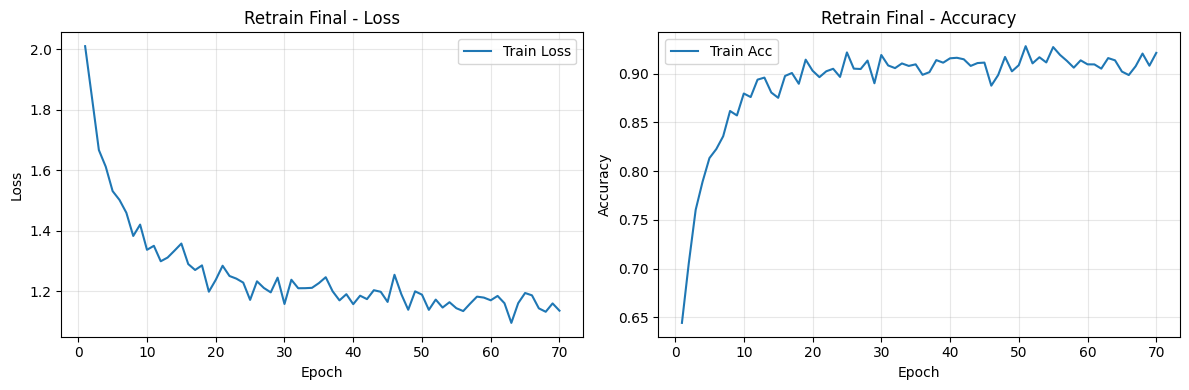

Kurva loss/akurasi retrain final disimpan di checkpoint_VIT-1/vit_b16-1_final_loss_acc_curve_20261011_181117.png


In [16]:
import matplotlib.pyplot as plt
h = final_history
ep = range(1, len(h['train_loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ep, h['train_loss'], label='Train Loss')
if 'val_loss' in h and len(h['val_loss']) > 0:
    axes[0].plot(ep, h['val_loss'], label='Val Loss')
axes[0].set_title('Retrain Final - Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(ep, h['train_acc'], label='Train Acc')
if 'val_acc' in h and len(h['val_acc']) > 0:
    axes[1].plot(ep, h['val_acc'], label='Val Acc')
axes[1].set_title('Retrain Final - Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
final_curve_path = os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_final_loss_acc_curve_{RUN_TIMESTAMP}.png')
plt.savefig(final_curve_path, dpi=150)
plt.show()
print(f"Kurva loss/akurasi retrain final disimpan di {final_curve_path}")

## Load model tersimpan tanpa retrain

In [10]:
import glob
import json
import numpy as np
import os

CHECKPOINT_DIR = 'checkpoint_VIT-1'
RUN_ID = 'vit_b16-1'

candidate_paths = sorted(glob.glob(os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_fold_splits_*.json')))
EVAL_FOLD_SPLIT_PATH = candidate_paths[-1]
print(f"Memuat pembagian fold dari {EVAL_FOLD_SPLIT_PATH}")

with open(EVAL_FOLD_SPLIT_PATH) as f:
    saved_splits = json.load(f)

class_names = saved_splits['class_names']
NUM_CLASSES = len(class_names)

filepath_to_idx = {path: i for i, (path, _) in enumerate(full_dataset.samples)}
loaded_val_indices = []
for fold in saved_splits['folds']:
    val_idx = np.array([filepath_to_idx[p] for p in fold['val_filepaths']])
    loaded_val_indices.append(val_idx)

N_FOLDS = len(loaded_val_indices)
print(f"Jumlah fold termuat: {N_FOLDS}")

test_idx = np.array([filepath_to_idx[p] for p in saved_splits['held_out_test_filepaths']])
print(f"Held-out test set termuat: {len(test_idx)} gambar")

Memuat pembagian fold dari checkpoint_VIT-1/vit_b16-1_fold_splits_20261012_115545.json
Jumlah fold termuat: 5
Held-out test set termuat: 1438 gambar


In [11]:
import torch.nn as nn
from torchvision import models
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
def build_stage1_model():
    weights = models.ViT_B_16_Weights.IMAGENET1K_SWAG_E2E_V1
    model = models.vit_b_16(weights=weights)
    for param in model.parameters():
        param.requires_grad = False
    model.heads = nn.Sequential(
        nn.Linear(768, 512),
        nn.ReLU(),
        nn.Dropout(0.4),
        nn.Linear(512, NUM_CLASSES)
    )
    for param in model.heads.parameters():
        param.requires_grad = True
    return model.to(device)

def load_fold_model(fold_num):
    model = build_stage1_model()
    ckpt_path = os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_fold{fold_num}.pth')
    state_dict = torch.load(ckpt_path, map_location=device)
    model.load_state_dict(state_dict)
    model.eval()
    return model

def load_final_model():
    model = build_stage1_model()
    ckpt_path = os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_final.pth')
    state_dict = torch.load(ckpt_path, map_location=device)
    model.load_state_dict(state_dict)
    model.eval()
    return model

Using device: cuda


In [12]:
from torch.utils.data import Dataset, DataLoader

class MapDataset(Dataset):
    def __init__(self, dataset, indices, transform=None):
        self.dataset = dataset
        self.indices = indices
        self.transform = transform
    def __getitem__(self, i):
        x, y = self.dataset[self.indices[i]]
        if self.transform: x = self.transform(x)
        return x, y
    def __len__(self): return len(self.indices)

BATCH_SIZE = 46
NUM_WORKERS = os.cpu_count()

loaded_models = []
loaded_fold_results = []

for fold_idx, val_idx in enumerate(loaded_val_indices):
    model = load_fold_model(fold_idx + 1)
    loaded_models.append(model)

    val_dataset = MapDataset(full_dataset, val_idx, transform=data_transforms['val'])
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

    y_true, y_pred = [], []
    with torch.no_grad():
        for inputs, labels in val_loader:
            outputs = model(inputs.to(device))
            preds = outputs.argmax(1).cpu().numpy()
            y_true.extend(labels.numpy())
            y_pred.extend(preds)

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    val_acc = (y_true == y_pred).mean()

    loaded_fold_results.append({
        'fold': fold_idx + 1,
        'val_acc': val_acc,
        'y_true': y_true,
        'y_pred': y_pred,
        'val_idx': val_idx,
    })
    print(f"Fold {fold_idx + 1} val acc dari model tersimpan: {val_acc:.4f}")

final_model = load_final_model()
print("Model final termuat dari", os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_final.pth'))

Fold 1 val acc dari model tersimpan: 0.8586
Fold 2 val acc dari model tersimpan: 0.8547
Fold 3 val acc dari model tersimpan: 0.8474
Fold 4 val acc dari model tersimpan: 0.8612
Fold 5 val acc dari model tersimpan: 0.8581
Model final termuat dari checkpoint_VIT-1/vit_b16-1_final.pth


In [13]:
import json, os
flagged = set(os.path.normpath(p) for p in json.load(open("near_dup_report/flagged_test_files.json")))
test_idx_asli = test_idx.copy()
test_idx = np.array([i for i in test_idx if os.path.normpath(full_dataset.samples[i][0]) not in flagged])
print(len(test_idx_asli), "->", len(test_idx))

1438 -> 1058


## Evaluasi akhir di held-out test set

In [14]:
from sklearn.metrics import classification_report

test_dataset = MapDataset(full_dataset, test_idx, transform=data_transforms['val'])
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)

final_model.eval()
y_true_test, y_pred_test = [], []
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = final_model(inputs)
        preds = outputs.argmax(1).cpu().numpy()
        y_true_test.extend(labels.numpy())
        y_pred_test.extend(preds)

y_true_test = np.array(y_true_test)
y_pred_test = np.array(y_pred_test)
test_acc = (y_true_test == y_pred_test).mean()
print(f"Akurasi held-out test (model final): {test_acc:.4f}\n")
print(classification_report(y_true_test, y_pred_test, target_names=class_names, digits=4))

Akurasi held-out test (model final): 0.8025

                                    precision    recall  f1-score   support

           Achaemenid architecture     0.9355    1.0000    0.9667        29
              Amazigh architecture     1.0000    0.8333    0.9091        12
  American Foursquare architecture     0.6818    0.6250    0.6522        24
          American craftsman style     0.5122    0.7500    0.6087        28
     Ancient Egyptian architecture     1.0000    1.0000    1.0000        15
        Architecture of Edo Period     0.9000    0.9000    0.9000        10
Architecture of the Joseon Dynasty     1.0000    1.0000    1.0000        14
  Architecture of the Qing Dynasty     1.0000    0.9375    0.9677        16
             Art Deco architecture     0.8372    0.8372    0.8372        43
          Art Nouveau architecture     0.7800    0.9070    0.8387        43
             Balinese architecture     1.0000    0.7857    0.8800        14
              Baroque architecture     0.7

In [15]:
import pandas as pd
os.makedirs("preds", exist_ok=True)
MODEL_NAME = "vit_b16-1"

assert len(test_idx_asli) == 1438
pred_ds = MapDataset(full_dataset, test_idx_asli, transform=data_transforms['val'])
pred_loader = DataLoader(pred_ds, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True)
final_model.eval()
yt_all, yp_all = [], []
with torch.no_grad():
    for inputs, labels in pred_loader:
        yp_all.extend(final_model(inputs.to(device)).argmax(1).cpu().numpy())
        yt_all.extend(labels.numpy())
yt_all, yp_all = np.array(yt_all), np.array(yp_all)
print(f"Akurasi test asli ({len(yt_all)} gambar): {(yt_all == yp_all).mean():.4f}")
pd.DataFrame({
    "filepath": [full_dataset.samples[i][0] for i in test_idx_asli],
    "y_true": yt_all, "y_pred": yp_all,
}).to_csv(f"preds/{MODEL_NAME}_test_preds.csv", index=False)

Akurasi test asli (1438 gambar): 0.8470


## Bootstrap 1000

In [16]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

assert 'y_true_test' in dir(), "Jalankan dulu cell 'Evaluasi akhir di held-out test set' sebelum ini."

y_true_all = y_true_test
y_pred_all = y_pred_test

N_BOOTSTRAP = 1000
rng = np.random.default_rng(42)
n_samples = len(y_true_all)

bootstrap_acc = np.zeros(N_BOOTSTRAP)
bootstrap_f1 = np.zeros(N_BOOTSTRAP)
bootstrap_precision = np.zeros(N_BOOTSTRAP)
bootstrap_recall = np.zeros(N_BOOTSTRAP)

for b in range(N_BOOTSTRAP):
    idx = rng.integers(0, n_samples, n_samples)
    bootstrap_acc[b] = accuracy_score(y_true_all[idx], y_pred_all[idx])
    bootstrap_f1[b] = f1_score(y_true_all[idx], y_pred_all[idx], average='macro')
    bootstrap_precision[b] = precision_score(y_true_all[idx], y_pred_all[idx], average='macro', zero_division=0)
    bootstrap_recall[b] = recall_score(y_true_all[idx], y_pred_all[idx], average='macro', zero_division=0)

acc_mean = bootstrap_acc.mean()
acc_ci_low, acc_ci_high = np.percentile(bootstrap_acc, [2.5, 97.5])
f1_mean = bootstrap_f1.mean()
f1_ci_low, f1_ci_high = np.percentile(bootstrap_f1, [2.5, 97.5])
precision_mean = bootstrap_precision.mean()
precision_ci_low, precision_ci_high = np.percentile(bootstrap_precision, [2.5, 97.5])
recall_mean = bootstrap_recall.mean()
recall_ci_low, recall_ci_high = np.percentile(bootstrap_recall, [2.5, 97.5])

print(f"[Held-out test] Akurasi bootstrap {N_BOOTSTRAP}x, mean {acc_mean:.4f}, 95% CI [{acc_ci_low:.4f}, {acc_ci_high:.4f}]")
print(f"[Held-out test] Macro F1 bootstrap {N_BOOTSTRAP}x, mean {f1_mean:.4f}, 95% CI [{f1_ci_low:.4f}, {f1_ci_high:.4f}]")
print(f"[Held-out test] Macro Precision bootstrap {N_BOOTSTRAP}x, mean {precision_mean:.4f}, 95% CI [{precision_ci_low:.4f}, {precision_ci_high:.4f}]")
print(f"[Held-out test] Macro Recall bootstrap {N_BOOTSTRAP}x, mean {recall_mean:.4f}, 95% CI [{recall_ci_low:.4f}, {recall_ci_high:.4f}]")

[Held-out test] Akurasi bootstrap 1000x, mean 0.8028, 95% CI [0.7779, 0.8270]
[Held-out test] Macro F1 bootstrap 1000x, mean 0.8097, 95% CI [0.7830, 0.8335]
[Held-out test] Macro Precision bootstrap 1000x, mean 0.8340, 95% CI [0.8082, 0.8558]
[Held-out test] Macro Recall bootstrap 1000x, mean 0.8092, 95% CI [0.7815, 0.8340]


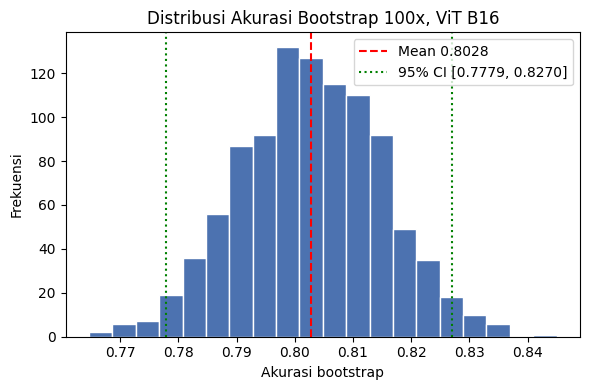

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.hist(bootstrap_acc, bins=20, color='#4C72B0', edgecolor='white')
plt.axvline(acc_mean, color='red', linestyle='--', label=f"Mean {acc_mean:.4f}")
plt.axvline(acc_ci_low, color='green', linestyle=':', label=f"95% CI [{acc_ci_low:.4f}, {acc_ci_high:.4f}]")
plt.axvline(acc_ci_high, color='green', linestyle=':')
plt.xlabel('Akurasi bootstrap')
plt.ylabel('Frekuensi')
plt.title('Distribusi Akurasi Bootstrap 100x, ViT B16')
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
import pandas as pd

df_bootstrap = pd.DataFrame({
    'iterasi': np.arange(1, N_BOOTSTRAP + 1),
    'accuracy': bootstrap_acc,
    'f1_macro': bootstrap_f1,
    'precision_macro': bootstrap_precision,
    'recall_macro': bootstrap_recall,
})

bootstrap_csv_path = os.path.join(CHECKPOINT_DIR, f'{RUN_ID}_bootstrap_test_{RUN_TIMESTAMP}.csv')
df_bootstrap.to_csv(bootstrap_csv_path, index=False)
print(f"Hasil bootstrap 100x tersimpan di {bootstrap_csv_path}")
df_bootstrap

Hasil bootstrap 100x tersimpan di checkpoint_VIT-1/vit_b16-1_bootstrap_test_20261012_115545.csv


,iterasi,accuracy,f1_macro,precision_macro,recall_macro
0,1,0.796786,0.801308,0.829577,0.798356
1,2,0.819471,0.822778,0.846956,0.822407
2,3,0.777883,0.775102,0.807014,0.778203
3,4,0.819471,0.831161,0.854102,0.826751
4,5,0.828922,0.845359,0.863584,0.845131
...,...,...,...,...,...
995,996,0.825142,0.825251,0.857076,0.818324
996,997,0.818526,0.813994,0.845049,0.808653
997,998,0.804348,0.813737,0.836576,0.810361
998,999,0.821361,0.832775,0.854556,0.830169


## Attention Rollout 

In [19]:
from PIL import Image 
def get_attention_maps(model, input_tensor):
    attn_maps = []

    def hook(module, inputs, output):
        attn_maps.append(output[1].detach())

    original_forwards = []
    handles = []
    for block in model.encoder.layers:
        attn_module = block.self_attention
        original_forward = attn_module.forward
        original_forwards.append((attn_module, original_forward))

        def patched_forward(query, key, value, original_forward=original_forward, **kwargs):
            kwargs['need_weights'] = True
            kwargs['average_attn_weights'] = True
            return original_forward(query, key, value, **kwargs)

        attn_module.forward = patched_forward
        handles.append(attn_module.register_forward_hook(hook))

    with torch.no_grad():
        model(input_tensor)

    for attn_module, original_forward in original_forwards:
        attn_module.forward = original_forward
    for h in handles:
        h.remove()

    return attn_maps


def attention_rollout(attn_maps, discard_ratio=0.0):
    num_tokens = attn_maps[0].size(-1)
    result = torch.eye(num_tokens).to(attn_maps[0].device)
    for attn in attn_maps:
        attn_fused = attn[0]
        if discard_ratio > 0:
            flat = attn_fused.view(attn_fused.size(0), -1)
            n_discard = int(flat.size(-1) * discard_ratio)
            _, idx = flat.topk(n_discard, -1, largest=False)
            flat.scatter_(-1, idx, 0)
        identity = torch.eye(num_tokens).to(attn_fused.device)
        a = (attn_fused + identity) / 2
        a = a / a.sum(dim=-1, keepdim=True)
        result = torch.matmul(a, result)
    mask = result[0, 1:]
    return mask


def rollout_to_heatmap(mask, grid_size, img_size):
    mask = mask.reshape(grid_size, grid_size).cpu().numpy()
    clip_val = np.percentile(mask, 95)
    mask = np.clip(mask, 0, clip_val)
    mask = (mask - mask.min()) / (mask.max() - mask.min() + 1e-8)
    mask_img = Image.fromarray((mask * 255).astype(np.uint8)).resize((img_size, img_size), Image.BILINEAR)
    return np.array(mask_img) / 255.0

In [20]:
rollout_model = final_model
GRID_SIZE = IMG_SIZE // 16

ROLLOUT_DIR = 'hasil_rollout'
os.makedirs(ROLLOUT_DIR, exist_ok=True)

samples_per_class = {}
for idx in test_idx:
    label = full_dataset.targets[idx]
    samples_per_class.setdefault(label, []).append(int(idx))

print(f"Rollout memakai model final, sampel diambil dari held-out test set ({len(test_idx)} gambar)")

Rollout memakai model final, sampel diambil dari held-out test set (1058 gambar)


In [21]:
for class_idx, class_name in enumerate(class_names):
    candidates = samples_per_class.get(class_idx, [])[:4]
    if not candidates:
        continue

    fig, axes = plt.subplots(len(candidates), 2, figsize=(6, 3 * len(candidates)))
    if len(candidates) == 1:
        axes = axes.reshape(1, 2)

    for row, sample_idx in enumerate(candidates):
        img, label = full_dataset[sample_idx]
        input_tensor = data_transforms['val'](img).unsqueeze(0).to(device)
        attn_maps = get_attention_maps(rollout_model, input_tensor)
        mask = attention_rollout(attn_maps)
        heatmap = rollout_to_heatmap(mask, GRID_SIZE, IMG_SIZE)

        display_img = img.resize((IMG_SIZE, IMG_SIZE))
        axes[row, 0].imshow(display_img)
        axes[row, 0].axis('off')
        axes[row, 0].set_title('Original')

        axes[row, 1].imshow(display_img)
        axes[row, 1].imshow(heatmap, cmap='jet', alpha=0.5)
        axes[row, 1].axis('off')
        axes[row, 1].set_title('Attention Rollout')

    fig.suptitle(class_name)
    plt.tight_layout()
    save_path = os.path.join(ROLLOUT_DIR, f'{class_name}_rollout.png')
    plt.savefig(save_path, dpi=150)
    plt.close(fig)
    print(f"Disimpan {save_path}")

Disimpan hasil_rollout/Achaemenid architecture_rollout.png
Disimpan hasil_rollout/Amazigh architecture_rollout.png
Disimpan hasil_rollout/American Foursquare architecture_rollout.png
Disimpan hasil_rollout/American craftsman style_rollout.png
Disimpan hasil_rollout/Ancient Egyptian architecture_rollout.png
Disimpan hasil_rollout/Architecture of Edo Period_rollout.png
Disimpan hasil_rollout/Architecture of the Joseon Dynasty_rollout.png
Disimpan hasil_rollout/Architecture of the Qing Dynasty_rollout.png
Disimpan hasil_rollout/Art Deco architecture_rollout.png
Disimpan hasil_rollout/Art Nouveau architecture_rollout.png
Disimpan hasil_rollout/Balinese architecture_rollout.png
Disimpan hasil_rollout/Baroque architecture_rollout.png
Disimpan hasil_rollout/Bauhaus architecture_rollout.png
Disimpan hasil_rollout/Beaux-Arts architecture_rollout.png
Disimpan hasil_rollout/Brutalist architecture_rollout.png
Disimpan hasil_rollout/Buddhist architecture_rollout.png
Disimpan hasil_rollout/Byzantine